# U.S. Occupational Wage Analysis

### Glassdoor: Decode U.S. wage inequality using hypothesis testing and regression analysis.

Glassdoor's economic research team benchmarks the compensation data reported on its platform against public labor market statistics. This project works with the U.S. Bureau of Labor Statistics Occupational Employment and Wage Statistics (OEWS) release as that public reference point.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

In [2]:
xls = pd.ExcelFile(r'C:\Users\lewis\Downloads\datasets\state_M2024_dl.xlsx')
xls.sheet_names

['state_M2024_dl', 'Field Descriptions', 'UpdateTime', 'Filler']

In [3]:
df = xls.parse(xls.sheet_names[0])
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,1,Alabama,2,AL,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,21.07,30.82,47.51,23520,30660,43830,64110,98810,NaN,NaN
1,1,Alabama,2,AL,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,48.39,68.5,98.03,51100,72870,100640,142480,203900,NaN,NaN
2,1,Alabama,2,AL,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,79.04,106.69,#,104950,130950,164400,221910,#,NaN,NaN
3,1,Alabama,2,AL,0,Cross-industry,cross-industry,1235,11-1021,General and Operations Managers,...,51.12,78.26,#,50410,74720,106330,162780,#,NaN,NaN
4,1,Alabama,2,AL,0,Cross-industry,cross-industry,1235,11-1031,Legislators,...,*,*,*,18270,20950,26990,41760,63900,True,NaN


In [4]:
field_descs = xls.parse(xls.sheet_names[1])
field_descs.head()

,May 2024 OEWS Estimates,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,Occupational Employment and Wage Statistics (O...,NaN,NaN
2,"Bureau of Labor Statistics, Department of Labor",NaN,NaN
3,website: www.bls.gov/oes,NaN,NaN
4,email: oewsinfo@bls.gov,NaN,NaN


In [5]:
df.columns = df.columns.str.lower()

In [6]:
df.shape

(37609, 32)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37609 entries, 0 to 37608
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area          37609 non-null  int64  
 1   area_title    37609 non-null  str    
 2   area_type     37609 non-null  int64  
 3   prim_state    37609 non-null  str    
 4   naics         37609 non-null  int64  
 5   naics_title   37609 non-null  str    
 6   i_group       37609 non-null  str    
 7   own_code      37609 non-null  int64  
 8   occ_code      37609 non-null  str    
 9   occ_title     37609 non-null  str    
 10  o_group       37609 non-null  str    
 11  tot_emp       37609 non-null  object 
 12  emp_prse      37609 non-null  object 
 13  jobs_1000     37609 non-null  object 
 14  loc_quotient  37609 non-null  object 
 15  pct_total     0 non-null      float64
 16  pct_rpt       0 non-null      float64
 17  h_mean        37609 non-null  object 
 18  a_mean        37609 non-null  object 

In [8]:
df.isna().sum()

area                0
area_title          0
area_type           0
prim_state          0
naics               0
naics_title         0
i_group             0
own_code            0
occ_code            0
occ_title           0
o_group             0
tot_emp             0
emp_prse            0
jobs_1000           0
loc_quotient        0
pct_total       37609
pct_rpt         37609
h_mean              0
a_mean              0
mean_prse           0
h_pct10             0
h_pct25             0
h_median            0
h_pct75             0
h_pct90             0
a_pct10             0
a_pct25             0
a_median            0
a_pct75             0
a_pct90             0
annual          34943
hourly          37447
dtype: int64

In [9]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area,37609.0,NaN,NaN,NaN,30.176633,16.823968,1.0,17.0,30.0,44.0,78.0
area_title,37609,54,California,829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_type,37609.0,NaN,NaN,NaN,2.026829,0.161585,2.0,2.0,2.0,2.0,3.0
prim_state,37609,54,CA,829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
naics,37609.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
naics_title,37609,1,Cross-industry,37609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
i_group,37609,1,cross-industry,37609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
own_code,37609.0,NaN,NaN,NaN,1235.0,0.0,1235.0,1235.0,1235.0,1235.0,1235.0
occ_code,37609,854,00-0000,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occ_title,37609,854,All Occupations,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
field_descs[8:41]

,May 2024 OEWS Estimates,Unnamed: 1,Unnamed: 2
8,Field,Field Description,NaN
9,area,"U.S. (99), state FIPS code, Metropolitan Stati...",NaN
10,area_title,Area name,NaN
11,area_type,Area type: 1= U.S.; 2= State; 3= U.S. Territor...,NaN
12,prim_state,"The primary state for the given area. ""US"" is ...",NaN
13,naics,North American Industry Classification System ...,NaN
14,naics_title,North American Industry Classification System ...,NaN
15,i_group,Industry level. Indicates cross-industry or NA...,NaN
16,own_code,Ownership type: 1= Federal Government; 2= Stat...,NaN
17,occ_code,The 6-digit Standard Occupational Classificati...,NaN


## Question 1: Highest and lowest paying states
**Q**: _Which U.S. states have the highest and lowest annual mean wages across all occupations?_

In [11]:
# Convert columns from object to numeric (invalid values become NaN)
for col in ['a_mean', 'tot_emp']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [12]:
# All-occupations mean wage per state
state_wages = (
    df[(df['o_group'] == 'total') & (df['area_type'] == 2)]
    .loc[:, ['prim_state', 'a_mean']]
    .dropna()
    .sort_values('a_mean', ascending=False)
    .reset_index(drop=True)
)

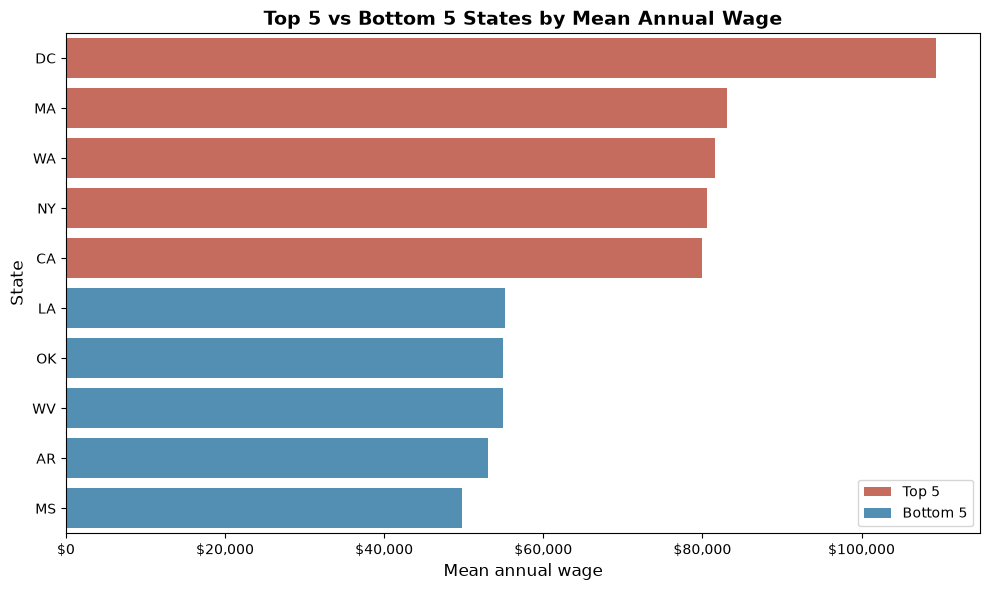

In [13]:
top_5 = state_wages.head(5).assign(group='Top 5')
bottom_5 = state_wages.tail(5).assign(group='Bottom 5')
combined = pd.concat([top_5, bottom_5])

plt.figure(figsize=(10, 6))

# Plot horizontal bar chart, top 5 above bottom 5
ax = sns.barplot(
    data=combined,
    x='a_mean',
    y='prim_state',
    hue='group',
    palette={'Top 5': '#d6604d', 'Bottom 5': '#4393c3'},
    dodge=False,
)

# Format x-axis as dollars
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

plt.title('Top 5 vs Bottom 5 States by Mean Annual Wage', fontsize=14, fontweight='bold')
plt.xlabel('Mean annual wage', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.legend(title=None)
plt.tight_layout()
plt.show()

### Q1 Findings

- The highest mean annual wages are in Washington, D.C. (\$109,420), Massachusetts and Washington, at about 82k to 109k USD. Note that D.C. is a district, not a state.
- The lowest are in Mississippi, Arkansas and West Virginia, at about 50k to 55k USD.
- The gap between the highest (D.C.) and lowest (Mississippi) is about \$60k, or about 120% of the lowest wage.
- Territories (Puerto Rico, Guam, etc.) are not included.

## Question 2: Occupation groups by weighted wage
**Q**: _Which occupation groups provide the best wage-to-employment efficiency?_

In [14]:
# Only keep rows with both values
valid = df.dropna(subset=['a_mean', 'tot_emp']).copy()
valid['total_payroll'] = valid['a_mean'] * valid['tot_emp']

major_groups_df = valid[valid['o_group'] == 'major'].groupby('occ_title').agg(
    total_payroll=('total_payroll', 'sum'),
    total_emp=('tot_emp', 'sum')
)

major_groups_df['weighted_wage'] = major_groups_df['total_payroll'] / major_groups_df['total_emp']

major_groups_df.sort_values('weighted_wage', ascending=False)

,total_payroll,total_emp,weighted_wage
occ_title,,,
Management Occupations,1.558615e+12,11013380.0,141520.160850
Legal Occupations,1.737530e+11,1263200.0,137549.895345
Computer and Mathematical Occupations,6.070804e+11,5205380.0,116625.568220
Healthcare Practitioners and Technical Occupations,1.012302e+12,9652130.0,104878.644765
Architecture and Engineering Occupations,2.680265e+11,2580980.0,103846.807569
Business and Financial Operations Occupations,9.739884e+11,10423640.0,93440.334269
"Life, Physical, and Social Science Occupations",1.303442e+11,1456210.0,89509.194004
"Arts, Design, Entertainment, Sports, and Media Occupations",1.619805e+11,2105780.0,76921.851143
Educational Instruction and Library Occupations,5.927969e+11,9010740.0,65787.809936


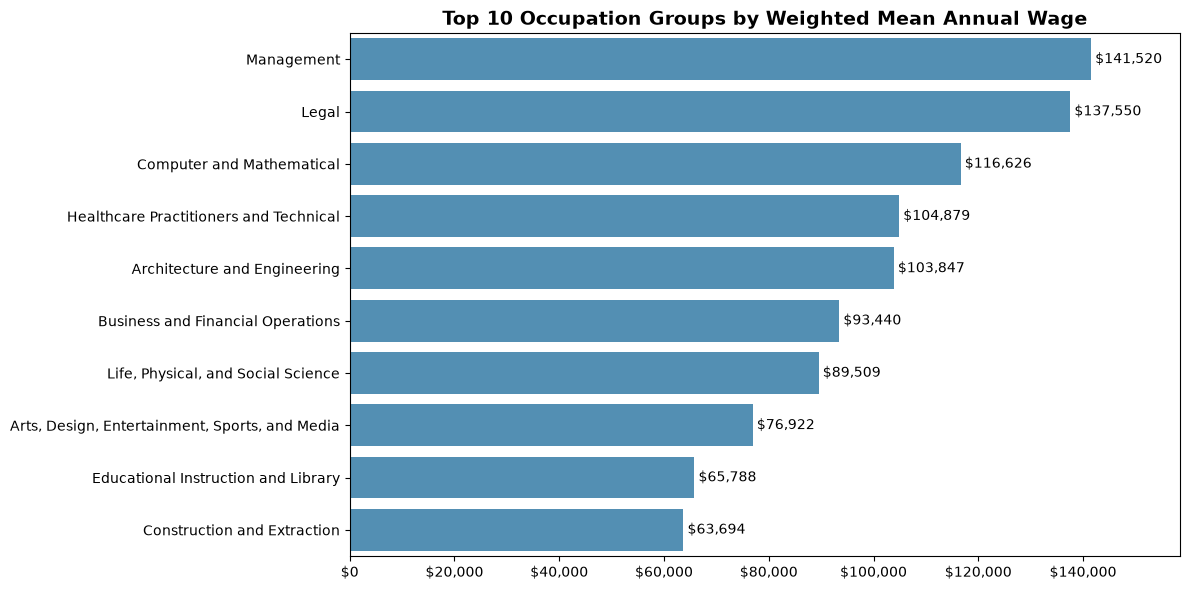

In [15]:
top_10 = (
    major_groups_df
    .sort_values('weighted_wage', ascending=False)
    .head(10)
    .reset_index()
)

top_10['occ_title'] = top_10['occ_title'].str.replace(' Occupations', '', regex=False)

plt.figure(figsize=(12, 6))

# Horizontal bars, highest at the top
ax = sns.barplot(
    data=top_10,
    x='weighted_wage',
    y='occ_title',
    order=top_10['occ_title'],
    color='#4393c3',
)

# Format x-axis as dollars
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

# Label each bar with its value
for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}', padding=3, fontsize=10)

plt.title('Top 10 Occupation Groups by Weighted Mean Annual Wage', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xlim(0, top_10['weighted_wage'].max() * 1.12)
plt.tight_layout()
plt.show()

### Q2 Findings

- Management has the highest employment-weighted mean wage at \$141.5k, followed by Legal and Computer/Mathematical.
- The lowest-paying major group is Food Preparation/Serving Related, at about \$36k, followed by Personal Care/Service.
- The top group pays about 3.9 times the bottom group.

## Qustion 3: California Occupation Distribution
**Q**: _Within California, how does employment vary among major occupation categories?_

In [16]:
cal_emp = df[(df['prim_state'] == 'CA') & (df['o_group'] == 'major')].groupby('occ_title')['tot_emp'].sum().reset_index()

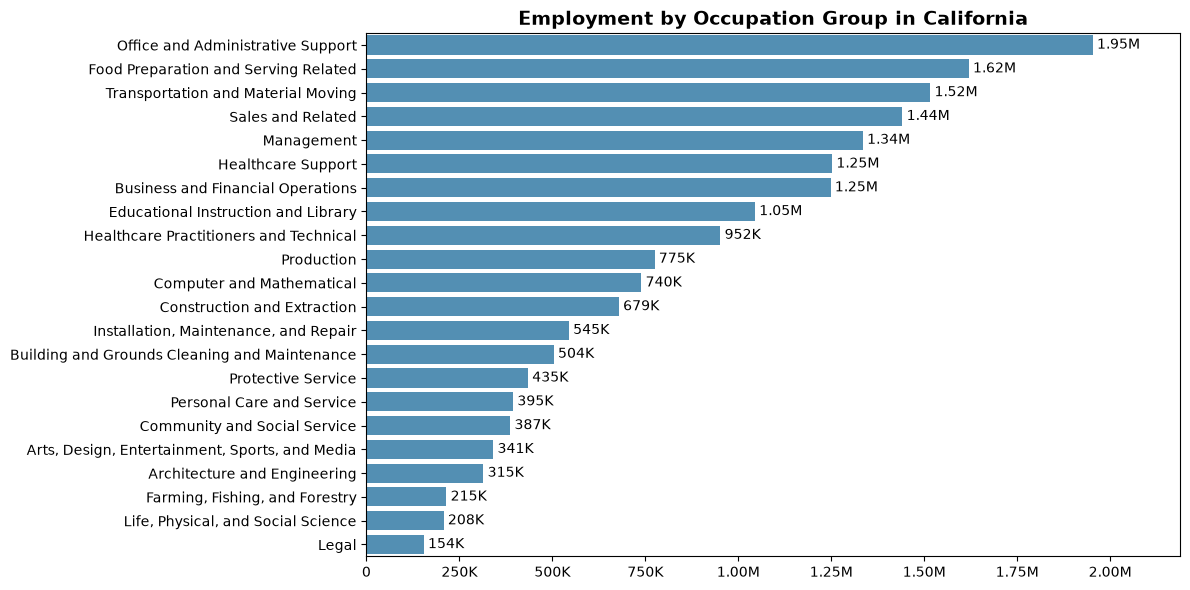

In [17]:
# Format numbers as K / M
def human_format(x, pos=None):
    if x >= 1_000_000:
        return f'{x / 1_000_000:.2f}M'
    if x >= 1_000:
        return f'{x / 1_000:.0f}K'
    return f'{x:.0f}'

cal_emp['occ_title'] = cal_emp['occ_title'].str.replace(' Occupations', '', regex=False)

# Sort so the largest group is on top
cal_emp = cal_emp.sort_values('tot_emp', ascending=False)

plt.figure(figsize=(12, 6))

# Horizontal bars, highest at the top
ax = sns.barplot(
    data=cal_emp,
    x='tot_emp',
    y='occ_title',
    order=cal_emp['occ_title'],
    color='#4393c3',
)

# Format x-axis with K / M
ax.xaxis.set_major_formatter(mtick.FuncFormatter(human_format))

# Label each bar with its value
for container in ax.containers:
    ax.bar_label(container, labels=[human_format(v) for v in container.datavalues], padding=3, fontsize=10)

plt.title('Employment by Occupation Group in California', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xlim(0, cal_emp['tot_emp'].max() * 1.12)
plt.tight_layout()
plt.show()

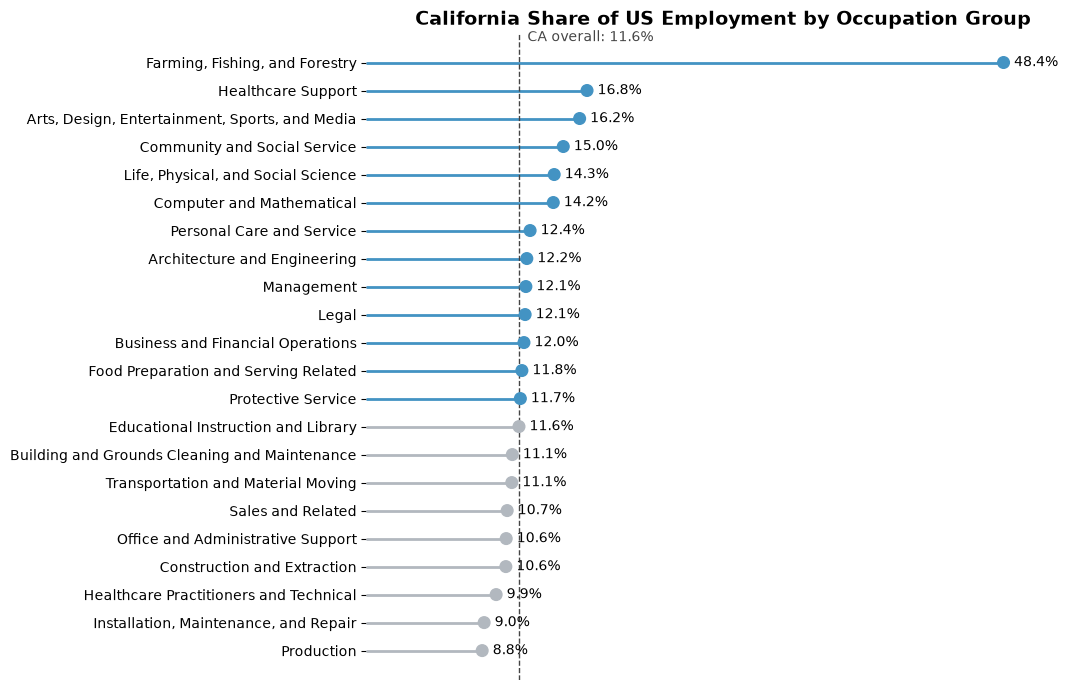

In [18]:
# Major groups only, with shortened titles
major = df[df['o_group'] == 'major'].copy()
major['occ_title'] = major['occ_title'].str.replace(' Occupations', '', regex=False)

# Total employment per group: all states vs. California
us_emp = major.groupby('occ_title')['tot_emp'].sum().rename('us')
ca_emp = major[major['prim_state'] == 'CA'].groupby('occ_title')['tot_emp'].sum().rename('ca')

# Combine into one table and compute California's share of each group
share_df = pd.concat([us_emp, ca_emp], axis=1).fillna(0)
share_df['share'] = share_df['ca'] / share_df['us']
share_df = share_df.sort_values('share', ascending=False).reset_index()

# California's overall share of US jobs
overall_share = share_df['ca'].sum() / share_df['us'].sum()

# Blue if above California's overall share, gray if below
colors = ['#4393c3' if s >= overall_share else '#b2b8bf' for s in share_df['share']]

fig, ax = plt.subplots(figsize=(11, 7))
y = range(len(share_df))

# Lollipop: thin stem plus dot
ax.hlines(y, 0, share_df['share'], color=colors, linewidth=2)
ax.scatter(share_df['share'], y, color=colors, s=70, zorder=3)

# Reference line at California's overall share of US jobs
ax.axvline(overall_share, color='#444444', linestyle='--', linewidth=1)
ax.text(overall_share, -0.9, f'  CA overall: {overall_share:.1%}', fontsize=10, color='#444444', va='center')

# Label each dot with its share
for yi, s in zip(y, share_df['share']):
    ax.text(s + 0.008, yi, f'{s:.1%}', va='center', fontsize=10)

ax.set_yticks(list(y))
ax.set_yticklabels(share_df['occ_title'])
ax.invert_yaxis()
ax.xaxis.set_visible(False)
ax.set_xlim(0, share_df['share'].max() * 1.12)

ax.set_title('California Share of US Employment by Occupation Group', fontsize=14, fontweight='bold')
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### Q3 Findings
- Office and Administrative Support is California’s largest major group at about 2M workers, followed by Food Preparation/Serving Related and Transportation/Material Moving.
- California holds 11.6% of US employment overall.
- It is over-represented in Farming, Fishing, and Forestry (48% of the US total) and under-represented in Production (9%).
- Dots above the overall-share line show where California’s workforce is concentrated relative to the nation.

## Question 4: Management vs Production Wages
**Q**: _Is there a significant wage difference between management and production occupations? (Two-sample T-test)_

In [19]:
mgmt = df.loc[df['occ_title'] == 'Management Occupations', 'a_mean'].dropna()
prod = df.loc[df['occ_title'] == 'Production Occupations', 'a_mean'].dropna()

# F-test for equal variances (two-sided)
f_stat = mgmt.var() / prod.var()
dfn, dfd = len(mgmt) - 1, len(prod) - 1
p_f = 2 * min(stats.f.cdf(f_stat, dfn, dfd), stats.f.sf(f_stat, dfn, dfd))
print(f'F = {f_stat:.2f}, p = {p_f:.4g}')

# Welch t-test, which doesn't assume equal variances
t_stat, p_val = stats.ttest_ind(mgmt, prod, equal_var=False)
print(f't = {t_stat:.2f}, p = {p_val:.4g}')

F = 12.65, p = 1.254e-16
t = 24.64, p = 1.634e-33


### Q4 Findings

- The mean state-level wage is 130k USD for management occupations and 51k USD for production occupations.
- The F-test for equal variances gives F = 12.65 (p = 1.25e-16). Since p is far below 0.05, we reject equal variances: management wages vary much more across states than production wages do.
- Because the variances differ, Welch's t-test is the appropriate test. It gives t = 24.64 (p = 1.63e-33).
- Since p is far below alpha = 0.05, we **reject the null hypothesis** of equal mean wages. The difference is statistically significant.
- The positive t-statistic means management pays more than production, by about \$79k on average.
- Caveat: each group has one wage per state (about 54 observations), so the sample is small. A p-value this small still makes the result very robust.

## Question 5: Wage vs Employment
**Q**: _Does higher employment predict lower wages? (Simple linear regression)_

In [20]:
detail = df[df['o_group'] == 'detailed'].dropna(subset=['tot_emp', 'a_mean']).copy()
detail['payroll'] = detail['tot_emp'] * detail['a_mean']

occ = detail.groupby('occ_title').agg(tot_emp=('tot_emp', 'sum'), payroll=('payroll', 'sum'))
occ['a_mean'] = occ['payroll'] / occ['tot_emp']
occ['log_emp'] = np.log(occ['tot_emp'])
occ['log_wage'] = np.log(occ['a_mean'])

model_log = sm.OLS(occ['log_wage'], sm.add_constant(occ['log_emp'])).fit()
print(model_log.summary())

                            OLS Regression Results                            
Dep. Variable:               log_wage   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     11.09
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           0.000906
Time:                        17:48:35   Log-Likelihood:                -522.47
No. Observations:                 822   AIC:                             1049.
Df Residuals:                     820   BIC:                             1058.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.4489      0.097    118.569      0.0

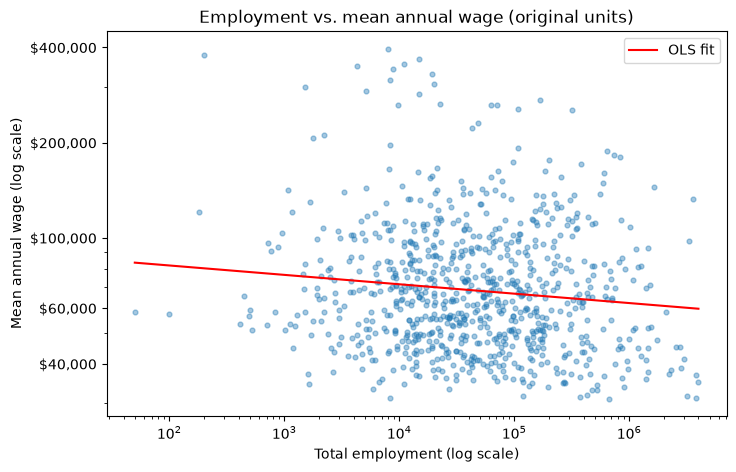

In [27]:
# Fitted line from the log-log model
x_line = np.linspace(occ['log_emp'].min(), occ['log_emp'].max(), 100)
y_line = model_log.params['const'] + model_log.params['log_emp'] * x_line

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(occ['tot_emp'], occ['a_mean'], alpha=0.4, s=12)
ax.plot(np.exp(x_line), np.exp(y_line), color='red', label='OLS fit')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_yticks([40000, 60000, 100000, 200000, 400000])
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel('Total employment (log scale)')
ax.set_ylabel('Mean annual wage (log scale)')
ax.set_title('Employment vs. mean annual wage (original units)')
ax.legend()
plt.show()

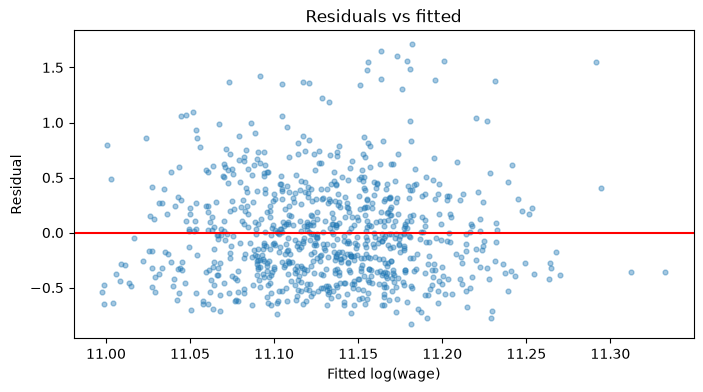

In [23]:
# Plot: residuals vs fitted values
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(model_log.fittedvalues, model_log.resid, alpha=0.4, s=12)
ax.axhline(0, color='red')
ax.set_xlabel('Fitted log(wage)')
ax.set_ylabel('Residual')
ax.set_title('Residuals vs fitted')
plt.show()

#### Q5 findings

- I regressed log mean annual wage on log total employment across 822 detailed occupations (national totals, one row per occupation).
- I used logs since employment is heavily right-skewed, so a few huge occupations would dominate a raw-scale fit.
- The slope is -0.0297 (95% CI: -0.047 to -0.012, p = 0.001). The relationship is **negative and statistically significant** at the 5% level, so we reject the null hypothesis that employment has no linear relationship with wages.
- Interpretation: a 1% increase in employment is associated with about a 0.03% lower mean wage. Doubling an occupation's employment goes with a wage about 2% lower, and a tenfold increase with a wage about 6.6% lower.
- R-squared is 0.013, so employment explains only about 1.3% of the variation in occupational wages. The effect is statistically detectable but **tiny in practical terms**.
- **Answer:** yes, higher employment predicts slightly lower wages, but employment is a very weak predictor.
- This is correlation, not causation. Occupations with low entry barriers tend to be both large and lower paid. Skill requirements, education and job type likely drive both employment and pay.
- Diagnostics: the residuals are right-skewed (skew = 0.94, Jarque-Bera p < 0.001), so they aren't normal. A cluster of high-wage occupations sits well above the fitted line, with residuals up to about +1.7 versus about -0.8 at the low end. The residual plot shows no clear funnel shape, and with 822 observations the slope estimate is still reasonably reliable. The fitted wages span only about 60k to 83k USD, which reflects how little variation employment explains.
- Limitations: this is a simple one-variable model. Adding occupation group or education level as controls would be a natural extension.